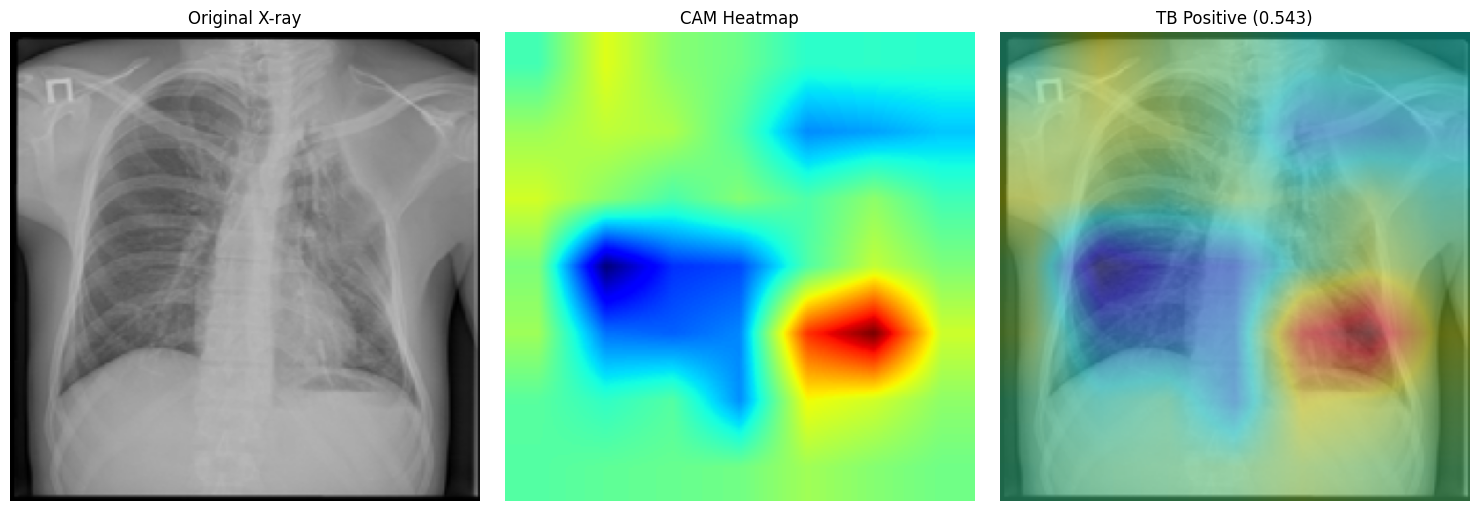

Prediction: TB Positive (0.5433)


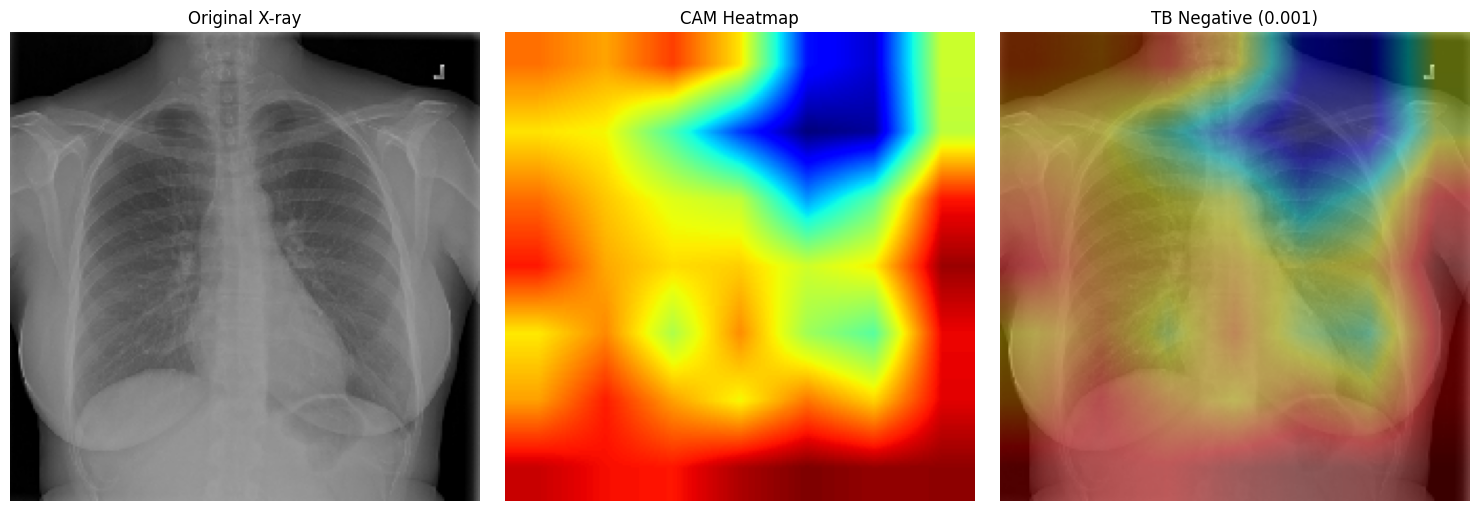

Prediction: TB Negative (0.0006)


In [14]:
def get_cam_heatmap(model, img_array):
    base = model.layers[1]
    img_tensor = tf.cast(img_array, tf.float32)
    conv_output = base(img_tensor, training=False).numpy()[0]  # (7, 7, 1280)
    dense_weights = model.layers[4].get_weights()[0][:, 0]    # (1280,)
    cam = np.dot(conv_output, dense_weights)                   # (7, 7)


    # even when absolute activations are low
    cam = cam - cam.min()
    if cam.max() > 0:
        cam = cam / cam.max()
    return cam

def overlay_gradcam(img_path, model):
    img = keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = keras.preprocessing.image.img_to_array(img) / 255.0
    img_array_expanded = np.expand_dims(img_array, axis=0)

    pred = model.predict(img_array_expanded, verbose=0)[0][0]
    label = "TB Positive" if pred >= 0.5 else "TB Negative"

    heatmap = get_cam_heatmap(model, img_array_expanded)
    heatmap_resized = cv2.resize(heatmap, (224, 224))
    heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)
    original = np.uint8(255 * img_array)
    superimposed = cv2.addWeighted(original, 0.6, heatmap_colored, 0.4, 0)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(original);            axes[0].set_title('Original X-ray');    axes[0].axis('off')
    axes[1].imshow(heatmap_resized, cmap='jet'); axes[1].set_title('CAM Heatmap');      axes[1].axis('off')
    axes[2].imshow(superimposed);         axes[2].set_title(f'{label} ({pred:.3f})'); axes[2].axis('off')
    plt.tight_layout()
    plt.savefig('/content/drive/MyDrive/EdgeTB_Project/gradcam_result.png', dpi=150)
    plt.show()
    print(f"Prediction: {label} ({pred:.4f})")

# TB positive
overlay_gradcam(
    '/content/drive/MyDrive/EdgeTB_Project/datasets/test/TB/Tuberculosis-112.png',
    model
)

# Normal
overlay_gradcam(
    '/content/drive/MyDrive/EdgeTB_Project/datasets/test/Normal/Normal-1044.png',
    model
)